# Title: Watt-Seer – The Personalized Energy Coach

## 1. Problem Statement
Many people receive energy bills without understanding what they did wrong or how to improve. This notebook demonstrates how GenAI can analyze usage and deliver personalized, human-friendly feedback.

## 2. Why GenAI?
Traditional graphs and tables don’t always help users make sense of their consumption. GenAI adds a layer of interpretation, turning raw data into clear narratives, recommendations, and even conversations.

## 3. Dataset Overview
The dataset is hourly data for a single home energy consumption, the   columns include hourly usage, and cost.

## 4. Analysis & Preprocessing
Code: data cleanup, resampling to daily, summarizing usage & cost

## 5. GenAI Integration
Prompt templates, example input/output
- Gemini is asked to find top usage days and explain them
- Structured output turned into visual/summary form


## 6. Conclusion
Reflect on impact, next steps, and potential to scale this to households or community energy planning.


In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/energy-data-2024-meter1/energy_hourly_data_2024_meter1.dat
/kaggle/input/energy-data-meter-2/energy_hourly_data_2024_meter2.dat
/kaggle/input/neighborbill/Neighbor-Bill.jpeg


#   Simple Kaggle Notebook to Analyze Energy Consumption Patterns
This notebook is a start for Energy Consumption


* Loading energy consumption data.
* Performing basic exploratory analysis.



# Energy Consumption Data Format (hourly)

The Energy Consumption data is in this format.

> start_time | end_time | consumption | provided_cost | start_minus_prev_end | end_minus_prev_end


In [2]:
import pandas as pd

# Load with tab separator and column names
df = pd.read_csv(
    "/kaggle/input/energy-data-meter-2/energy_hourly_data_2024_meter2.dat",
    sep="\t",
    names=["start_time", "end_time", "consumption", "provided_cost", 
           "start_minus_prev_end", "end_minus_prev_end"],
    header=None,
    on_bad_lines='skip'
)

# Define exact datetime format (includes time zone offset)
datetime_format = "%Y-%m-%d %H:%M:%S%z"

# Explicit parse
df['start_time'] = pd.to_datetime(df['start_time'], utc=True,format=datetime_format, errors='coerce')
df['end_time'] = pd.to_datetime(df['end_time'], utc=True, format=datetime_format, errors='coerce')

# Drop bad rows
df.dropna(subset=['start_time', 'end_time'], inplace=True)

hourly_df = df.copy()
# Set index and select key columns
df.set_index('start_time', inplace=True)
df = df[['consumption', 'provided_cost']]


## 📘 Step: Convert Hourly Data to Daily Totals
This step prepares the data for daily-level analysis by ensuring numeric types and resampling:

✅ First, we ensure that the 'consumption' and 'provided_cost' columns are properly converted to numeric format. This helps avoid issues caused by non-numeric entries (e.g., missing or corrupted data).

🕐 Then, we resample the hourly energy data to daily & monthly totals using Pandas' resample('D'). This gives us a daily and monthly view of:

Total energy consumption (kWh)

Total cost ($)

This daily summary will be used for identifying high-usage days, comparing costs, and correlating usage with external factors like temperature.
The monthly summary will be used to compare against a neighbors bill.



In [3]:
# Ensure correct types
df['consumption'] = pd.to_numeric(df['consumption'], errors='coerce')
df['provided_cost'] = pd.to_numeric(df['provided_cost'], errors='coerce')
# Resample hourly data to daily totals (IMPORTANT)
daily_data = df.resample('D').agg({
    'consumption': 'sum',
    'provided_cost': 'sum'
})
# 4. Resample to monthly totals (month-end)
monthly_data = df.resample('ME').agg({
    'consumption': 'sum',
    'provided_cost': 'sum'
}).round(2)

print(daily_data.head())
print(monthly_data.head())

                           consumption  provided_cost
start_time                                           
2024-01-01 00:00:00+00:00       22.064       3.661962
2024-01-02 00:00:00+00:00       70.308      11.669019
2024-01-03 00:00:00+00:00       53.101       8.813173
2024-01-04 00:00:00+00:00       51.451       8.539322
2024-01-05 00:00:00+00:00       57.207       9.494646
                           consumption  provided_cost
start_time                                           
2024-01-31 00:00:00+00:00      2252.38         373.83
2024-02-29 00:00:00+00:00      1259.13         208.98
2024-03-31 00:00:00+00:00      1323.14         219.60
2024-04-30 00:00:00+00:00       663.37         110.10
2024-05-31 00:00:00+00:00       588.09          97.61


# 📊 Visualizing Daily Energy Consumption and Cost with Dual Y-Axis Plot
This section uses matplotlib to create a dual-axis line chart that visualizes daily energy consumption (kWh) and cost ($) on the same plot, but with separate Y-axes for clarity.
This uses a twin axis plot so you can display both energy consumption and cost over time without overcrowding one axis.

fig.autofmt_xdate() automatically rotates the X-axis date labels to prevent overlap.

The combined legend includes both data series, making the chart easy to interpret.

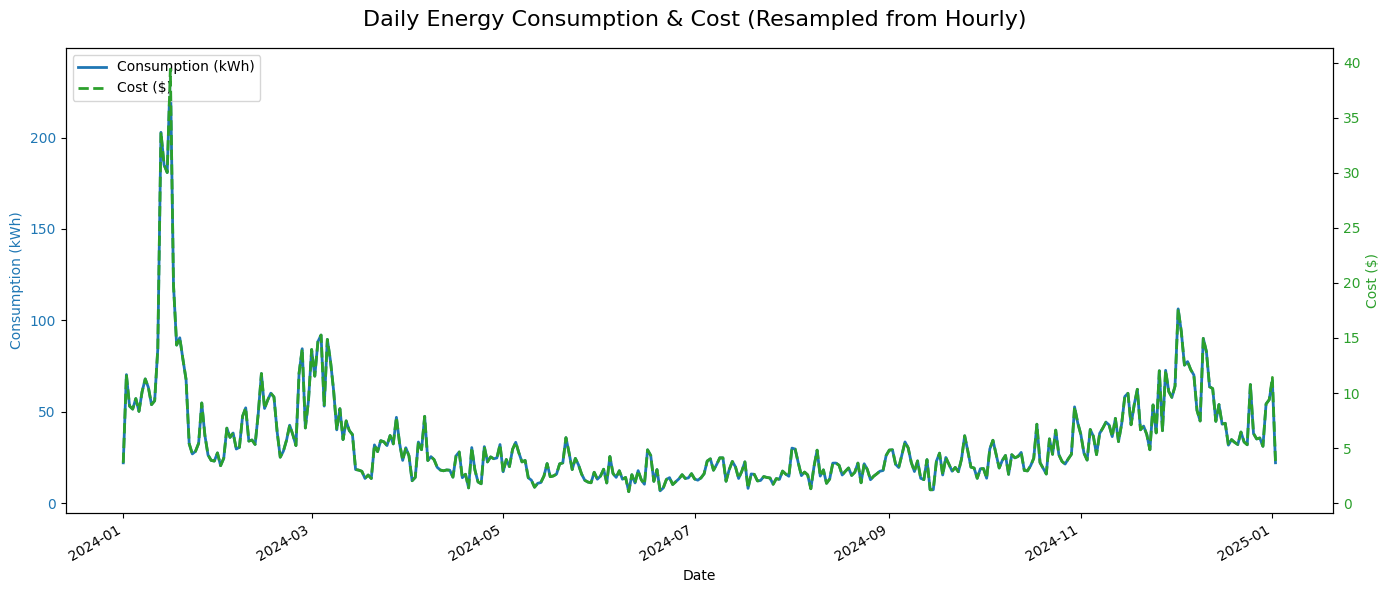

In [4]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(14, 6))

# Plot daily energy consumption
color1 = 'tab:blue'
ax1.set_xlabel("Date")
ax1.set_ylabel("Consumption (kWh)", color=color1)
ax1.plot(daily_data.index, daily_data['consumption'], label='Consumption (kWh)', color=color1, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color1)

# Second y-axis for cost
ax2 = ax1.twinx()
color2 = 'tab:green'
ax2.set_ylabel("Cost ($)", color=color2)
ax2.plot(daily_data.index, daily_data['provided_cost'], label='Cost ($)', color=color2, linestyle='dashed', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color2)

# Grid, legend, title
fig.suptitle("Daily Energy Consumption & Cost (Resampled from Hourly)", fontsize=16)
fig.autofmt_xdate()  # rotates date labels

# Combined legend from both axes
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='upper left')

plt.tight_layout()
plt.show()


# SDK install and other steps from Day 1
Install the google-genai (from Day 1) https://www.kaggle.com/code/markishere/day-1-prompting
Set up a retry helper. This allows you to "Run all" without worrying about per-minute quota.

In [5]:
!pip uninstall -qqy jupyterlab kfp 2>/dev/null  # Remove unused conflicting packages
!pip install -U -q "google-genai==1.7.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.7/144.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.9/100.9 kB 4.9 MB/s eta 0:00:00


In [6]:
from google import genai
from google.genai import types

genai.__version__

'1.7.0'

In [7]:
from google.api_core import retry


is_retriable = lambda e: (isinstance(e, genai.errors.APIError) and e.code in {429, 503})

genai.models.Models.generate_content = retry.Retry(
    predicate=is_retriable)(genai.models.Models.generate_content)

# Set up your API key¶
To run the following cell, your API key must be stored it in a Kaggle secret named GOOGLE_API_KEY.

If you don't already have an API key, you can grab one from AI Studio. You can find detailed instructions in the docs.

To make the key available through Kaggle secrets, choose Secrets from the Add-ons menu and follow the instructions to add your key or enable it for this notebook.

The Python SDK uses a Client object to make requests to the API. The client lets you control which back-end to use (between the Gemini API and Vertex AI) and handles authentication (the API key).

We run though a simple client.models.list() to make sure everything is in order.

In [8]:

# Send to Gemini
import os

GOOGLE_API_KEY = UserSecretsClient().get_secret("GOOGLE_API_KEY")

client = genai.Client(api_key=GOOGLE_API_KEY)
for m in client.models.list():
    print(m.name)


models/chat-bison-001
models/text-bison-001
models/embedding-gecko-001
models/gemini-1.0-pro-vision-latest
models/gemini-pro-vision
models/gemini-1.5-pro-latest
models/gemini-1.5-pro-001
models/gemini-1.5-pro-002
models/gemini-1.5-pro
models/gemini-1.5-flash-latest
models/gemini-1.5-flash-001
models/gemini-1.5-flash-001-tuning
models/gemini-1.5-flash
models/gemini-1.5-flash-002
models/gemini-1.5-flash-8b
models/gemini-1.5-flash-8b-001
models/gemini-1.5-flash-8b-latest
models/gemini-1.5-flash-8b-exp-0827
models/gemini-1.5-flash-8b-exp-0924
models/gemini-2.5-pro-exp-03-25
models/gemini-2.5-pro-preview-03-25
models/gemini-2.5-flash-preview-04-17
models/gemini-2.0-flash-exp
models/gemini-2.0-flash
models/gemini-2.0-flash-001
models/gemini-2.0-flash-exp-image-generation
models/gemini-2.0-flash-lite-001
models/gemini-2.0-flash-lite
models/gemini-2.0-flash-lite-preview-02-05
models/gemini-2.0-flash-lite-preview
models/gemini-2.0-pro-exp
models/gemini-2.0-pro-exp-02-05
models/gemini-exp-1206
m

# Calling Gemini with the data summary

* Let us build a simple prompt to give a friendly explanation of what the summary of data means.
* Let us Use the gemini-2.5-pro-exp-03-25 model
* Let us see what Gemini returns
* This is a simple example of Document understanding




📊 We first call daily_data.describe() to get a statistical summary of daily energy consumption and cost — including mean, min, max, and standard deviation.

🧠 This summary is sent as part of a prompt to Gemini 2.5 Pro, asking it to generate a short, conversational explanation.

📄 The result is displayed using IPython.display.Markdown() so it appears formatted and readable directly in the notebook.



In [9]:
from IPython.display import Markdown
daily_summary = daily_data.describe().round(2).to_string()

prompt = f"""
Here’s a summary of my home's daily energy usage and cost:

{daily_summary}

Please give me a friendly explanation of what this means in a couple of paragraphs
"""


response = client.models.generate_content(model="gemini-2.5-pro-exp-03-25", contents=prompt)
Markdown(response.text)


Okay, let's break down what these numbers tell us about your home's energy habits over the 368 days measured!

Think of it like this: on an **average** day, your home used about 33.11 kilowatt-hours (kWh) of energy, which cost you around $5.50. However, the **median** (the 50% mark) shows that on a more "typical" day, half the time you used *less* than 25.38 kWh (costing $4.21) and half the time you used *more*. The average being higher than this typical value suggests you have some days with significantly higher energy use that pull the average up.

Your energy use isn't the same every day – far from it! It varies quite a bit. Your lowest energy day used only 6.29 kWh (costing $1.04), while your highest usage day spiked to a very high 237.43 kWh (costing $39.41). Most of your days (the middle 50%, between the 25% and 75% marks) fall within a range of about 17 kWh to 40 kWh per day, costing between roughly $2.85 and $6.58. So, while you have a common range, there are definitely days that are much lower or significantly higher in terms of energy consumption and cost.

# 📊 Energy Usage Insights with Gemini AI
We make a prompt a bit more descriptive. This uses Google Gemini to summarize household energy consumption based on descriptive statistics. It helps identify typical usage patterns, detect anomalies, and offer efficiency tips—even under a fixed-rate energy plan.

This prompt provides the AI model with:

* A summary of the energy data
* Clear instructions on the type of insights expected
* We add a few shot examples to say what we would like to see.





In [10]:


# Generate summary stats
summary_stats = daily_data.describe().round(2).to_string()

# Build Gemini prompt with few-shot examples
prompt = f"""
You are an energy advisor helping households understand their energy usage and improve efficiency, even under fixed-rate plans.

Here are two examples of how you respond to data summaries:

---
**Example 1 – Summary Stats:**
            kWh  Cost ($)
count     30.00     30.00
mean      22.50      2.25
std        4.20      0.42
min       15.30      1.53
25%       19.00      1.90
50%       22.00      2.20
75%       26.00      2.60
max       32.00      3.20

**Your Analysis:**
The household's typical daily usage is around 22.5 kWh, costing $2.25 per day. There is moderate variability, with usage ranging from 15.3 to 32 kWh. A few high-usage days suggest possible overuse—perhaps laundry or heating. Suggestions: replace older appliances with energy-efficient models, use timers for high-draw devices, and consider weatherproofing to reduce HVAC needs.

---
**Example 2 – Summary Stats:**
            kWh  Cost ($)
count     30.00     30.00
mean      12.10      1.21
std        2.50      0.25
min        7.80      0.78
25%       10.00      1.00
50%       12.00      1.20
75%       14.00      1.40
max       17.50      1.75

**Your Analysis:**
This household maintains relatively low energy usage, averaging 12.1 kWh daily. Costs are steady, and standard deviation is low. The occasional spike to 17.5 kWh could be linked to cooking or entertainment use. Suggest unplugging idle electronics and using smart plugs for tracking further savings opportunities.

---
Now here is the real household's summary stats:

{summary_stats}

Please summarize key insights, including:
- Typical daily usage and cost
- Any significant variations or outliers
- Suggestions to reduce energy waste or improve efficiency (even if rate is fixed)
"""

# Generate response
response = client.models.generate_content(
    model="gemini-2.5-pro-exp-03-25",
    contents=prompt
)

# Render in notebook
Markdown(response.text)


Okay, let's analyze this household's energy usage based on the provided statistics.

**Your Analysis:**

This household's average daily energy consumption is **33.11 kWh**, resulting in a typical daily cost of **$5.50**. However, there's **significant variation** in day-to-day usage, as indicated by the high standard deviation (26.62 kWh) which is nearly as large as the average itself.

While half the days see usage below 25.38 kWh, the average is pulled higher by periods of much greater consumption. The **maximum usage of 237.43 kWh** on a single day is exceptionally high and stands out as a major outlier, costing nearly $40 for that day alone. This suggests specific events or inefficient systems driving consumption dramatically higher at times.

**Suggestions for Improvement (Even on a Fixed Rate):**

1.  **Investigate High Usage Days:** The massive difference between typical days and the maximum usage day (and likely other high days above the 75th percentile mark of ~40 kWh) points to specific causes. Potential culprits include:
    *   Electric heating/cooling systems working overtime (especially emergency/auxiliary heat).
    *   Pool pump/heater operation.
    *   Electric vehicle charging patterns.
    *   Faulty high-draw appliances (e.g., water heater, well pump).
2.  **HVAC Optimization:** Heating and cooling are often the biggest energy users. Consider:
    *   Installing a smart thermostat to optimize schedules.
    *   Checking/improving insulation and sealing air leaks (windows, doors, attics).
    *   Regularly changing air filters for efficiency.
3.  **Appliance Audit:** Review major appliances (refrigerator, water heater, washer/dryer). Older models can be significant energy drains. Consider ENERGY STAR replacements when upgrading.
4.  **Water Heating:** If using an electric water heater, check the thermostat setting (120°F/49°C is often sufficient) and consider insulating the tank and hot water pipes.
5.  **Reduce Phantom Load:** While likely not the cause of the *extreme* peaks, unplugging chargers, entertainment systems, and computers when not in use, or using smart power strips, can still contribute to overall savings.

Focusing on identifying the cause of the exceptionally high usage days (like the 237 kWh outlier) and optimizing HVAC performance will likely yield the most significant reductions in energy waste.

# 💬 Chat-Based Energy Insight Generator Using Gemini
This module leverages Google Gemini's chat capabilities to provide continuous, interactive analysis of household energy data. Instead of a one-time prompt, we establish a chat session with a system role and allow back-and-forth questions and refinement—like working with a skilled energy analyst chatbot.

🧠 Purpose
Interpret summary statistics of energy usage and cost

Extract trends, detect anomalies, and suggest improvements

Enable continuous querying for deeper analysis and visualization

Mimic the feel of chatting with a knowledgeable energy advisor

Since this is a chat session, you can now follow up with:


* “What might be causing high energy usage on weekends?”
* “Can you suggest 3 ways to cut 10% off this usage?”
* “Generate a weekly line chart.”


In [11]:
MODEL_ID = "gemini-2.5-pro-exp-03-25"
system_prompt = (
    "You are a skilled Energy Analyst. You will help with a variety of tasks related to energy usage, "
    "including creating graphs, analyzing data, identifying trends, and providing actionable insights."
)

chat = client.chats.create(
    model=MODEL_ID,
    config=types.GenerateContentConfig(
        system_instruction=system_prompt
    )
)

prompt = f"""
You will summarize household energy usage data clearly and concisely, highlighting key insights.

Examples:

Input:
Daily Energy Usage (kWh) - Mean: 35, Median: 33, Std Dev: 4
Daily Cost ($) - Mean: 7.00, Median: 6.60, Std Dev: 0.80

Output:
The household uses approximately 35 kWh of energy daily, costing around $7 per day. The median daily usage is slightly lower at 33 kWh, suggesting occasional high-consumption days. The energy costs remain relatively stable with minor variations, indicated by a standard deviation of $0.80.

Input:
Daily Energy Usage (kWh) - Mean: 42, Median: 41, Std Dev: 3
Daily Cost ($) - Mean: 8.40, Median: 8.20, Std Dev: 0.60

Output:
On average, daily energy usage is around 42 kWh with a typical daily cost of about $8.40. The narrow standard deviation (3 kWh for usage and $0.60 for costs) shows consistent daily energy consumption and costs.

Now, summarize the following data similarly:

{summary_stats}
"""

response = chat.send_message(prompt)
Markdown(response.text)


Okay, here is a summary based on the provided statistics:

On average, the household consumes approximately **33.1 kWh** of energy per day, with an average daily cost of **$5.50**. However, the median consumption (**25.4 kWh**) and median cost (**$4.21**) are notably lower than the averages. This significant difference indicates that while most days fall into a lower usage range, there are occasional days with substantially higher energy consumption and cost that pull the average up. The high standard deviations (**26.6 kWh** for consumption and **$4.42** for cost) further confirm considerable day-to-day variability in energy usage and expenditure.

# 🔍 Continuing the Chat: Analyzing Top and Lowest Energy Usage Days
After establishing a chat session with Gemini as an energy analyst, we can continue the conversation by exploring extreme usage days. 

This step involves identifying the highest and lowest consumption days from the dataset and requesting targeted insights and recommendations.

Because we’re continuing the same chat, Gemini retains context from previous messages (like overall trends as well as needing to act as an analyst).


This enables multi-turn conversations, such as:

* “Are any of these top days weekends?”
* “Could weather or holidays be influencing these?”

In [12]:
top_days = daily_data.sort_values('consumption', ascending=False).head(5)
low_days = daily_data.sort_values('consumption').head(5)

summary = f"""
Top energy usage days:\n{top_days.round(2).to_string(index=True)}

Lowest energy usage days:\n{low_days.round(2).to_string(index=True)}

Now provide insights and suggestions.
"""

response = chat.send_message(summary)











# 📊 Visual Summary of High Energy Usage Days with Insights
This section introduces a custom utility function, display_energy_insight, that combines Markdown-based narrative summaries, data tables, and bar chart visualizations to highlight key insights—enhanced with AI-generated commentary using Google Gemini.

## 🧠 Why Use This?
This approach blends:

* Quantitative summaries (via Pandas)
* Narrative insights (via Gemini AI)
* Visual storytelling (via Matplotlib)


## 📘 Extreme Winter Energy Peaks


**Total for Top 5 Days:**

- 🔋 Energy Consumed: **925.50 kWh**
- 💵 Cost Incurred: **$153.60**

Okay, analyzing the top and bottom usage days alongside the summary statistics provides much clearer insights:

**Key Insights:**

1.  **Extreme Seasonal Variation:** There's a massive difference between peak winter usage (mid-January) and low usage during milder months (June, August, September). The highest day (237 kWh) used over 37 times more energy than the lowest day (6.3 kWh).
2.  **Heating Drives Peak Consumption:** The top 5 usage days are clustered tightly in mid-January. This strongly suggests that heating demands during cold weather are the primary driver of the highest energy consumption and costs for this household. Electric heating (like a furnace, heat pump running auxiliary heat, or space heaters) is likely a major factor on these days.
3.  **Significant Cost Impact of Peak Days:** The highest consumption days resulted in extremely high daily costs (up to nearly $40), drastically impacting the overall average cost. Addressing these peak usage periods is key to managing energy expenses.
4.  **Potential for Savings in Milder Seasons:** The very low usage days indicate periods where minimal heating or cooling was required, showcasing the baseline energy needs of the household (likely lighting, refrigeration, electronics).

**Actionable Suggestions:**

1.  **Focus on Winter Heating Efficiency:**
    *   **Thermostat Management:** Consider a programmable or smart thermostat to automatically lower temperatures overnight or when away. Even a few degrees can save significant energy.
    *   **Heating System Check-up:** Ensure the heating system (furnace, heat pump) is operating efficiently. Schedule regular maintenance and change filters frequently. If the system is old, evaluate the cost-effectiveness of an upgrade to a more efficient model.
    *   **Air Sealing & Insulation:** Check for drafts around windows, doors, and electrical outlets. Improve insulation, especially in the attic, to reduce heat loss. This is often a very cost-effective measure.
    *   **Supplemental Heat:** If using electric space heaters, use them sparingly, only heat occupied rooms, and ensure they are not left unattended. Avoid using them as a primary heat source if possible.

2.  **Investigate Peak Day Activities (Beyond Weather):** While weather is the most likely cause, briefly consider if any unusual activities occurred on those specific mid-January dates that could have contributed (e.g., hosting guests, large projects).

3.  **Maintain Low Usage Habits:** Continue energy-saving practices during milder months (efficient lighting, unplugging unused electronics, etc.) to keep the baseline usage low.

4.  **Monitor Usage:** Continue monitoring daily or weekly usage, especially during winter months, to see the impact of any changes made and to identify any future unexplained spikes.

By focusing primarily on reducing heating energy consumption during the coldest periods, the household can significantly lower its peak usage days and reduce overall annual energy costs.

,consumption,provided_cost
start_time,,
2024-01-16 00:00:00+00:00,237.428000,39.405925
2024-01-13 00:00:00+00:00,202.870000,33.670334
2024-01-14 00:00:00+00:00,185.065000,30.715238
2024-01-15 00:00:00+00:00,180.857000,30.016836
2024-01-17 00:00:00+00:00,119.278000,19.796570


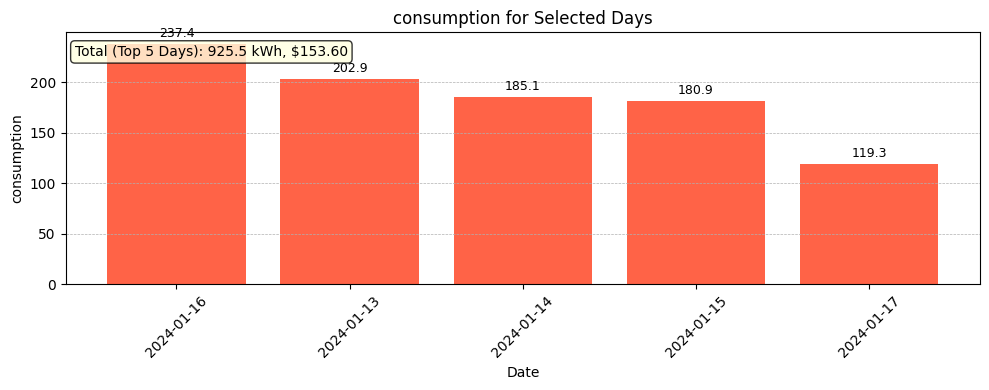

In [13]:
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

from IPython.display import Markdown, display
import matplotlib.pyplot as plt

def display_energy_insight(
    title: str,
    insight_text: str,
    df: pd.DataFrame = None,
    df_caption: str = None,
    plot_column: str = None,
    plot_color: str = "skyblue"
):
    # Display title and insight
    display(Markdown(f"## 📘 {title}"))
    display(Markdown(insight_text))

    # Display DataFrame if provided
    if df is not None:
        styled_df = df.style.set_caption(df_caption)
        display(styled_df)

        # Format the index for cleaner labels if it's datetime
        if isinstance(df.index[0], pd.Timestamp):
            df = df.copy()
            df.index = df.index.strftime('%Y-%m-%d')  # or '%b %d, %Y'

        # Plotting section
        if plot_column and plot_column in df.columns:
            plt.figure(figsize=(10, 4))
            bars = plt.bar(df.index, df[plot_column], color=plot_color)

            plt.title(f"{plot_column} for Selected Days")
            plt.xlabel("Date")
            plt.ylabel(plot_column)
            plt.xticks(rotation=45)
            plt.grid(True, axis='y', linestyle='--', linewidth=0.5)

            # Add value labels above bars
            for bar in bars:
                height = bar.get_height()
                plt.annotate(f'{height:.1f}',
                             xy=(bar.get_x() + bar.get_width() / 2, height),
                             xytext=(0, 3),
                             textcoords="offset points",
                             ha='center', va='bottom', fontsize=9)

            # Add summary annotation box
            if 'consumption' in df.columns and 'provided_cost' in df.columns:
                total_kwh = df['consumption'].sum()
                total_cost = df['provided_cost'].sum()

                summary = f"Total (Top {len(df)} Days): {total_kwh:.1f} kWh, ${total_cost:.2f}"
                plt.annotate(summary,
                             xy=(0.01, 0.95),
                             xycoords='axes fraction',
                             ha='left', va='top',
                             fontsize=10,
                             bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

            plt.tight_layout()
            plt.show()


# Calculate sum of consumption and cost
total_kwh = top_days['consumption'].sum()
total_cost = top_days['provided_cost'].sum()
summary_text = f"""
**Total for Top 5 Days:**

- 🔋 Energy Consumed: **{total_kwh:.2f} kWh**
- 💵 Cost Incurred: **${total_cost:.2f}**

"""

# Combine with Gemini insights
combined_insight = summary_text + response.text

insight_text = combined_insight  
top_days = daily_data.sort_values('consumption', ascending=False).head(5)
# Make a copy so we don't change the original
top_days_formatted = top_days.copy()

# Format the datetime index
top_days_formatted.index = top_days_formatted.index.strftime('%Y-%m-%d')  # or '%b %d, %Y'

display_energy_insight(
    title="Extreme Winter Energy Peaks",
    insight_text=combined_insight,  # includes Gemini response + total summary
    df=top_days,
    df_caption="Top 5 Energy Usage Days",
    plot_column='consumption',
    plot_color="tomato"
)


# 🌦️ Linking Energy Spikes to Weather: Gathering Data for Gemini
Let us tell Gemini more about when the top 5 energy usage days occurred—and what the weather was like on those days. Understanding external conditions, like cold snaps, can provide context for high consumption.

We use the Open-Meteo Archive API, which offers free historical weather data, to get hourly temperatures for each of the top usage days.

In [14]:
import pandas as pd
import requests

# Location (example: Portland, OR)
latitude = 45.52
longitude = -122.67

# Dates of interest
top_usage_dates = [
    "2024-01-13",
    "2024-01-14",
    "2024-01-15",
    "2024-01-16",
    "2024-01-17"
]
weather_data = []

for date in top_usage_dates:
    url = f"https://archive-api.open-meteo.com/v1/archive?" \
          f"latitude={latitude}&longitude={longitude}" \
          f"&start_date={date}&end_date={date}" \
          f"&hourly=temperature_2m" \
          f"&temperature_unit=fahrenheit"
    
    response = requests.get(url)
    data = response.json()
    
    df = pd.DataFrame({
        "datetime": data['hourly']['time'],
        "temperature_F": data['hourly']['temperature_2m']
    })
    df['date'] = pd.to_datetime(date)
    weather_data.append(df)

# Combine into single DataFrame
weather_df = pd.concat(weather_data, ignore_index=True)
weather_df['datetime'] = pd.to_datetime(weather_df['datetime'])
weather_df.head(5)

,datetime,temperature_F,date
0,2024-01-13 00:00:00,32.7,2024-01-13
1,2024-01-13 01:00:00,26.6,2024-01-13
2,2024-01-13 02:00:00,21.9,2024-01-13
3,2024-01-13 03:00:00,18.9,2024-01-13
4,2024-01-13 04:00:00,17.5,2024-01-13


In [15]:
top_days_str = top_days[['consumption', 'provided_cost']].round(2).to_string()
weather_summary = weather_df.groupby(weather_df['datetime'].dt.date)['temperature_F'].describe().round(1).to_string()



# ✨ Let Us Give Gemini the Whole Context… and See the Magic Unfold
After identifying the top 5 energy usage days and collecting hourly weather data for those same days, we now combine everything into one comprehensive prompt. By giving Gemini the full picture, we allow it to reason about possible environmental causes, human behavior, and efficiency strategies.

This is where the magic unfolds—when AI brings data to life with contextual insight.

In [16]:
top_day_weather_prompt = f"""
I am analyzing my top 5 highest energy usage days:

Energy usage summary:
{top_days_str}

Weather conditions on those days (hourly temperature in Fahrenheit):
{weather_summary}

Please help me understand:
- How might the temperature patterns explain my high energy usage?
- Are there behavioral or system-level improvements I can consider?
"""
response = chat.send_message(top_day_weather_prompt)
Markdown(response.text)

Okay, let's break down the relationship between the temperature and your high energy usage on those days.

**How Temperature Patterns Explain High Energy Usage:**

1.  **Extreme Cold Requires Constant Heating:** The temperatures on January 13th through 16th were exceptionally low. Mean temperatures hovered in the mid-teens (°F), with minimums dipping into single digits or low teens. Even the daily highs barely reached freezing or stayed well below it.
    *   **High Heating Load:** In such conditions, your home loses heat rapidly to the outside. Your heating system had to work almost constantly and at maximum capacity just to maintain a baseline indoor temperature.
    *   **Heat Pumps & Auxiliary Heat:** If you use a heat pump, these temperatures are likely far below its efficient operating range. This forces the system to rely heavily on its **auxiliary heat** (often electric resistance coils, like a giant toaster). Auxiliary electric heat consumes significantly *more* electricity than the heat pump operating normally. This is a very common cause of extreme electricity bills during deep freezes.
    *   **Furnaces:** Even standard furnaces (gas, oil, propane) run much more frequently and for longer durations in severe cold, increasing fuel consumption (and potentially electricity for blowers). If your primary heating is electric resistance (like baseboards or an electric furnace), the energy usage would skyrocket directly with the heating demand.
2.  **Slight Moderation Shows Impact:** Notice that January 17th was significantly warmer (mean temp ~30°F, max ~45°F) compared to the previous four days. Correspondingly, your energy usage dropped significantly (from 180-237 kWh down to 119 kWh). While still high compared to your overall average, this clearly demonstrates how much those *extremely* cold days (10-15°F means) pushed your heating system into overdrive compared to merely "cold" days (around freezing).

**Behavioral and System-Level Improvements to Consider:**

**Behavioral (Immediate Actions):**

1.  **Thermostat Strategy During Extreme Cold:**
    *   **Slight Setback:** Even lowering the thermostat by 1-2 degrees Fahrenheit during extreme cold snaps can yield noticeable savings, especially if you're using auxiliary electric heat.
    *   **Night/Away Setbacks:** Ensure you are using setbacks (lowering the temperature) when asleep or away from home. A smart or programmable thermostat automates this.
2.  **Minimize Drafts:** Use draft stoppers under doors, ensure windows are fully closed and latched. Check fireplace dampers. Temporarily covering drafty windows with plastic film or heavy blankets during severe cold can help.
3.  **Strategic Use of Space Heaters:** If you use electric space heaters for supplemental warmth, be aware they consume a lot of electricity (typically 1.5 kWh per hour). Use them targetedly in occupied rooms rather than trying to heat large areas or relying on them excessively. *Never* use them as a primary heat source if you can avoid it.
4.  **Use Window Coverings:** Keep curtains and blinds closed, especially at night, to add a small layer of insulation.

**System-Level (Longer-Term Improvements):**

1.  **Heating System Maintenance:**
    *   **Regular Service:** Get your furnace or heat pump professionally serviced annually. A clean, well-maintained system runs more efficiently.
    *   **Filter Changes:** Change air filters regularly (monthly during heavy use). A clogged filter restricts airflow, making the system work harder.
    *   **Heat Pump Check:** If you have a heat pump, ensure it's configured correctly and the auxiliary heat isn't engaging prematurely or unnecessarily.
2.  **Air Sealing:** This is often one of the most cost-effective improvements. Seal air leaks around windows, doors, electrical outlets, plumbing penetrations, attic hatches, and sill plates. Reducing air infiltration means your heated air stays inside longer.
3.  **Insulation:**
    *   **Attic:** Ensure you have adequate attic insulation (levels vary by climate zone, but often R-49 to R-60 is recommended). This is critical for preventing heat loss.
    *   **Walls & Crawlspace/Basement:** Check insulation levels in walls and foundation areas (basement walls, crawlspace).
4.  **Smart Thermostat:** Can optimize heating schedules, potentially learn when to use auxiliary heat more intelligently (on some advanced models/systems), and provide better usage data.
5.  **System Upgrade:** If your heating system is old or inefficient (especially if it relies heavily on electric resistance heat), consider upgrading to a modern high-efficiency heat pump (especially a cold-climate model if applicable) or furnace. This is a significant investment but offers the largest potential savings during winter.
6.  **Window/Door Upgrades:** If your windows and doors are old, drafty, and single-paned, upgrading to modern, energy-efficient units can significantly reduce heat loss, though this is also a major investment.

**In summary:** Your highest usage days are directly linked to the intense heating demand caused by extremely low outdoor temperatures, likely exacerbated if your system relied heavily on less efficient auxiliary electric heat. Focusing on both thermostat behavior during cold snaps and system-level improvements like air sealing, insulation, and heating system maintenance/efficiency offers the best path to reducing these costly peaks.

In [17]:
weather_energy =  response.text

# Day 1, we learned about Evaluating the AI, 

The following code is thanks to Mark who helped us all with 5 Days of Kaggle Examples. 
This one from [Day 1 about evaluation and structured output](https://www.kaggle.com/code/markishere/day-1-evaluation-and-structured-output)


# Define an evaluator
For a task like this, you may wish to evaluate a number of aspects, like how well the model followed the prompt ("instruction following"), whether it included relevant data in the prompt ("groundedness"), how easy the text is to read ("fluency"), or other factors like "verbosity" or "quality".

You can instruct an LLM to perform these tasks in a similar manner to how you would instruct a human rater: with a clear definition and assessment rubric.

In this step, you define an evaluation agent using a pre-written "summarisation" prompt and use it to gauge the quality of the generated summary.


In [18]:
import enum

# Define the evaluation prompt
SUMMARY_PROMPT = """\
# Instruction
You are an expert evaluator. Your task is to evaluate the quality of the responses generated by AI models.
We will provide you with the user input and an AI-generated responses.
You should first read the user input carefully for analyzing the task, and then evaluate the quality of the responses based on the Criteria provided in the Evaluation section below.
You will assign the response a rating following the Rating Rubric and Evaluation Steps. Give step-by-step explanations for your rating, and only choose ratings from the Rating Rubric.

# Evaluation
## Metric Definition
You will be assessing summarization quality, which measures the overall ability to summarize text. Pay special attention to length constraints, such as in X words or in Y sentences. The instruction for performing a summarization task and the context to be summarized are provided in the user prompt. The response should be shorter than the text in the context. The response should not contain information that is not present in the context.

## Criteria
Instruction following: The response demonstrates a clear understanding of the summarization task instructions, satisfying all of the instruction's requirements.
Groundedness: The response contains information included only in the context. The response does not reference any outside information.
Conciseness: The response summarizes the relevant details in the original text without a significant loss in key information without being too verbose or terse.
Fluency: The response is well-organized and easy to read.

## Rating Rubric
5: (Very good). The summary follows instructions, is grounded, is concise, and fluent.
4: (Good). The summary follows instructions, is grounded, concise, and fluent.
3: (Ok). The summary mostly follows instructions, is grounded, but is not very concise and is not fluent.
2: (Bad). The summary is grounded, but does not follow the instructions.
1: (Very bad). The summary is not grounded.

## Evaluation Steps
STEP 1: Assess the response in aspects of instruction following, groundedness, conciseness, and verbosity according to the criteria.
STEP 2: Score based on the rubric.

# User Inputs and AI-generated Response
## User Inputs

### Prompt
{prompt}

## AI-generated Response
{response}
"""

# Define a structured enum class to capture the result.
class SummaryRating(enum.Enum):
  VERY_GOOD = '5'
  GOOD = '4'
  OK = '3'
  BAD = '2'
  VERY_BAD = '1'


def eval_summary(prompt, ai_response):
  """Evaluate the generated analysis against the prompt used."""

  chat = client.chats.create(model='gemini-2.5-pro-exp-03-25')

  # Generate the full text response.
  response = chat.send_message(
      message=SUMMARY_PROMPT.format(prompt=prompt, response=ai_response)
  )
  verbose_eval = response.text

  # Coerce into the desired structure.
  structured_output_config = types.GenerateContentConfig(
      response_mime_type="text/x.enum",
      response_schema=SummaryRating,
  )
  response = chat.send_message(
      message="Convert the final score.",
      config=structured_output_config,
  )
  structured_eval = response.parsed
    
  return verbose_eval, structured_eval


text_eval, struct_eval = eval_summary(prompt=top_day_weather_prompt, ai_response=weather_energy)
Markdown(text_eval)

*   **Instruction following:** The response directly addresses both parts of the user's request. It analyzes the relationship between the provided temperature and energy usage data and offers both behavioral and system-level improvement suggestions based on that analysis.
*   **Groundedness:** The response grounds its core analysis in the provided data, correctly identifying the correlation between the extremely low temperatures on Jan 13-16 and the highest energy usage, and noting the drop in usage on the relatively warmer Jan 17. The discussion about heating system types (heat pumps/auxiliary heat) is an inference based on common causes of high *electrical* energy usage in cold weather, which is reasonable given the context, although not explicitly stated in the input data. The improvement suggestions are general best practices relevant to the situation identified (high heating costs in cold weather) rather than derived directly from the numerical data itself, but they are appropriate and grounded in the user's expressed problem.
*   **Conciseness:** The response is comprehensive but well-structured and avoids unnecessary verbosity. It explains the link between temperature and usage clearly and provides a good range of actionable suggestions without being overwhelming. The summary paragraph effectively recaps the key points.
*   **Fluency:** The response is well-written, uses clear language, and is organized logically with headings and bullet points, making it easy to read and understand.

**Rating:** 5

**Reasoning:**
The response perfectly follows the instructions by analyzing the provided data to explain the high energy usage and offering relevant improvement suggestions. The analysis is directly based on the correlation evident in the data (low temperatures correlating with high usage). While it makes reasonable inferences about potential heating system types (like auxiliary heat) to explain the magnitude of electrical usage, this is presented appropriately and adds value. The suggestions provided are standard, relevant, and directly address the user's goal of reducing high energy consumption during cold weather. The response is well-structured, clear, and concise.

In [19]:
struct_eval

<SummaryRating.VERY_GOOD: '5'>

# 🧾  Evaluating Heating Efficiency Upgrade Options Using Gemini AI
This prompt (options_prompt) is designed to engage Gemini in a structured analysis of three potential home heating upgrades following unusually high electricity usage during a cold spell. The goal is to receive a comparative breakdown of effectiveness, cost, long-term savings, and practical considerations for each solution.
Expected Output:
A structured and data-informed response from Gemini including:

A comparison table or bullet list per option

Insights on cost-benefit tradeoffs

Recommended sequence or combination of upgrades

Cautions or scenarios where one option may be less suitable

This is part of a broader Watt-Seer Coach use case for generating AI-personalized home energy optimization advice.

In [20]:
options_prompt = """
My home had extremely high electricity usage during a recent cold spell. On the top five days, my daily energy consumption was between 120–240 kWh, significantly higher than my average. 

As you suggested the heat pump electric resistance mode, contributed to this spike during subfreezing temperatures.

I'm exploring three options to improve heating efficiency and reduce future energy bills:

a) Sealing and insulating the home better  
b) Adding a supplemental heat source like a pellet stove  
c) Replacing the current heat pump with a newer, more efficient model

Can you help me:

- Compare the effectiveness, upfront cost, and long-term savings potential of each option  
- Suggest what combination might work best in a cold climate  
- Mention any drawbacks or limitations I should be aware of
- Provide some estimates of costs in USD

Assume I am on a fixed-rate electric plan with high winter usage, and I'm open to multi-step solutions.
"""
response = chat.send_message(options_prompt)
Markdown(response.text)

Okay, let's break down these three options to address your high winter energy usage from the heat pump's auxiliary mode.

**Comparison of Options:**

| Feature                 | a) Sealing & Insulation       | b) Supplemental Heat (Pellet Stove) | c) New Efficient Heat Pump   |
| :---------------------- | :---------------------------- | :---------------------------------- | :--------------------------- |
| **Primary Action**      | Reduces heat *loss* from home | Provides alternative heat source    | Improves heating *efficiency* |
| **Effectiveness**       | High (fundamental fix)        | High (for reducing electric use)  | High (especially cold-climate models) |
| **Impact on Aux Heat**  | Reduces *need* for aux heat   | *Replaces* aux heat runtime       | Drastically reduces *reliance* on aux heat |
| **Upfront Cost (Est.)** | Low-High ($100s - $15,000+)  | Moderate-High ($3k - $6k+)       | High ($8k - $20k+)          |
| **Long-Term Savings** | High & Consistent             | Variable (depends on pellet cost) | High (lower electricity use) |
| **Summer Benefit?**     | Yes (reduces cooling load)    | No                                | Yes (more efficient cooling) |
| **Effort Required**     | Low (ongoing), Moderate (install) | High (fueling, cleaning)        | Low (ongoing)                |
| **Complexity**          | Low-Moderate                  | Moderate (install, operation)   | High (install)               |

**Detailed Breakdown:**

**a) Sealing and Insulating:**

*   **Effectiveness:** Very high. This tackles the root cause – your house losing heat too quickly, forcing *any* heating system to work harder. Reducing heat loss directly reduces how often your heat pump (and its auxiliary heat) needs to run.
*   **Upfront Cost:** Highly variable.
    *   *DIY Air Sealing:* Low ($100 - $500 for caulk, foam, weatherstripping).
    *   *Professional Air Sealing:* Moderate ($500 - $2,000+). Often identifies leaks you wouldn't find.
    *   *Attic Insulation:* Moderate ($1,000 - $3,000+). Often the most cost-effective insulation upgrade.
    *   *Wall/Basement Insulation:* High ($5,000 - $15,000+). More disruptive.
*   **Long-Term Savings:** High and permanent. Reduces energy needed for both heating *and* cooling. Payback can be relatively quick for air sealing and attic insulation.
*   **Drawbacks:** Can be disruptive during installation. Doesn't improve the *inherent* efficiency of your existing heat pump, just reduces its workload. Maximum benefit might require a professional energy audit ($300-$600) to identify key areas.

**b) Supplemental Heat (Pellet Stove):**

*   **Effectiveness:** Effective at shifting heating *cost* away from expensive peak electricity (used by aux heat) to potentially cheaper pellet fuel. Can heat a significant area.
*   **Upfront Cost:** Moderate to High ($2,000 - $5,000 for the stove + $1,000 - $2,000+ for installation/venting). Ongoing cost for pellets ($250-$500+ per ton, usage varies).
*   **Long-Term Savings:** Highly dependent on the relative cost of electricity vs. pellets in your area, and how much you use it. If pellets are significantly cheaper per BTU than your electric rate, savings can be substantial during cold months.
*   **Drawbacks:** Requires physical effort (loading pellets, cleaning ash). Requires storage space for pellets. Pellet prices fluctuate. Doesn't improve home's thermal envelope or AC efficiency. Heat distribution might be uneven unless centrally located or using fans. Adds combustion emissions (though relatively low for pellets). Another appliance to maintain.
*   **Limitation:** Only helps with heating costs; no benefit for summer cooling.

**c) Replacing Heat Pump:**

*   **Effectiveness:** High, *especially* if upgrading to a modern **cold-climate heat pump**. These models are designed to operate efficiently down to much lower temperatures (even 5°F or lower) before needing auxiliary heat, directly addressing your core problem. Also improves cooling efficiency (higher SEER2 rating).
*   **Upfront Cost:** High ($8,000 - $20,000+). Costs vary significantly based on brand, efficiency (HSPF2 rating), size, and installation complexity. **Crucially, check for significant federal tax credits (via Inflation Reduction Act) and potential state/utility rebates that can lower this cost substantially.**
*   **Long-Term Savings:** High potential. Drastically reduces the expensive auxiliary heat usage. Lowers overall electricity consumption for heating and cooling year-round.
*   **Drawbacks:** Highest upfront cost (even with incentives). Doesn't fix underlying home leakiness (though a properly sized unit helps). Still relies on electricity, just uses much less. Installation is complex.
*   **Limitation:** May *still* occasionally use auxiliary heat in the absolute most extreme temperatures, but far, far less often than an older or standard model.

**Suggested Combination for a Cold Climate:**

1.  **Start with (a) Sealing and Insulation:** This is the foundational step. Improving your home's thermal envelope makes *any* heating system perform better and reduces the overall heating load. Focus on cost-effective measures first: air sealing and attic insulation. Get an energy audit if possible to prioritize.
2.  **Strongly Consider (c) New Cold-Climate Heat Pump:** If your current heat pump is older or not designed for cold climates, upgrading is likely the most impactful *long-term* solution to directly combat the auxiliary heat issue. The combination of a tighter house (from step 1) and a highly efficient system that rarely uses auxiliary heat offers the best overall efficiency and lowest running costs. Explore the available incentives thoroughly – they can make this option much more feasible.
3.  **Evaluate (b) Pellet Stove as an Alternative/Supplement IF:**
    *   The upfront cost of a new heat pump (even with incentives) is currently prohibitive.
    *   You have access to relatively inexpensive and stable pellet fuel.
    *   You desire fuel source diversity or backup heat independent of the electric grid (though pellet stoves still need electricity to run feeders/fans).
    *   You are prepared for the manual operation and maintenance involved.

**Ideal Multi-Step Solution:**

Prioritize **(a) Sealing and Insulation** first, as it benefits everything. Then, if budget allows, invest in **(c) a New Cold-Climate Heat Pump**, taking full advantage of incentives. This combination provides the most robust, lowest-effort, and efficient year-round solution for a cold climate. A pellet stove (b) becomes a secondary consideration based on the specific financial constraints and lifestyle preferences mentioned above.

# Comparing to the Neighbor with Image Understanding

Neighbor only keeps paper bills. It has a graph of energy usage for all of 2024. How well can Gemini read it

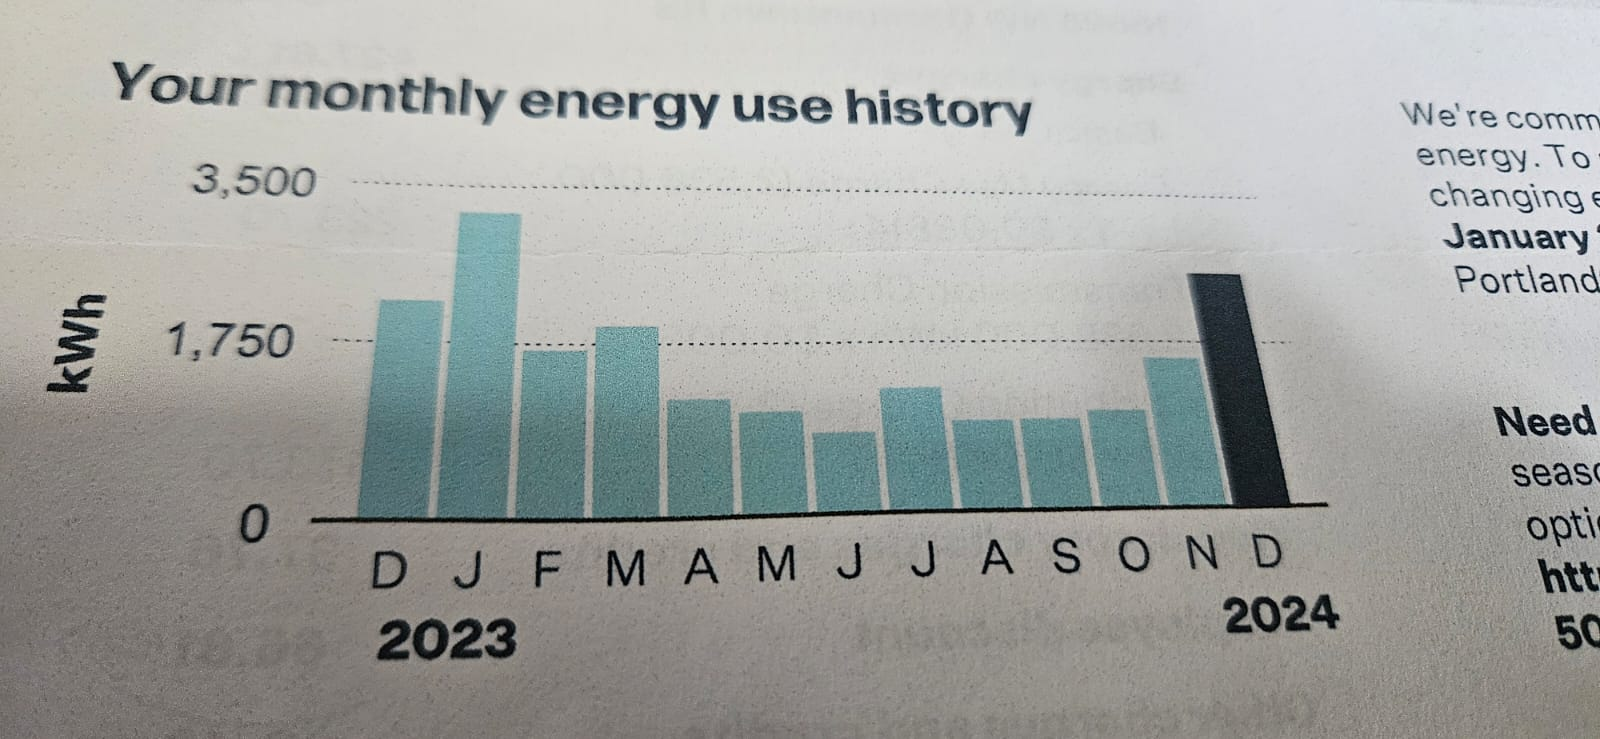

In [21]:
import PIL
from IPython.display import display, Image, Markdown, Audio
Image('/kaggle/input/neighborbill/Neighbor-Bill.jpeg', width=500)

In [22]:
from google import genai
from google.genai import types
from IPython.display import display, Image, Markdown, Audio

genai.__version__

'1.7.0'

In [23]:

# 5. Optional: Format index for readability (e.g., "January 2024")
monthly_data.index = monthly_data.index.strftime('%B %Y')

# 6. Print or send to Gemini
monthly_text = monthly_data.to_string()
print(monthly_text)


                consumption  provided_cost
start_time                                
January 2024        2252.38         373.83
February 2024       1259.13         208.98
March 2024          1323.14         219.60
April 2024           663.37         110.10
May 2024             588.09          97.61
June 2024            440.75          73.15
July 2024            509.68          84.59
August 2024          569.72          94.56
September 2024       643.60         106.82
October 2024         813.59         135.03
November 2024       1340.26         222.44
December 2024       1692.75         280.95
January 2025          89.19          15.25



# 📄 Extracting Monthly Energy Usage from a Utility Bill Image with Gemini
Purpose:
This cell uses Gemini's image understanding and document extraction capabilities to process a scanned utility bill (Neighbor-Bill.jpeg) and extract monthly energy usage (in kWh).

Context:
As part of the Watt-Seer Coach project, understanding how energy usage varies over time—especially for comparison between households—is critical. This example uses a neighbor’s bill to extract structured data (month-wise usage) from an unstructured JPEG file

See Image understanding example in [here as bonus day extra api features](https://www.kaggle.com/code/markishere/bonus-day-extra-api-features-to-try) 

In [24]:
prompt = [
  f"This is my neighbor’s electric bill. Please extract the monthly energy usage (in kWh) for all the months. EXAMPLE Output December 2023: ~1000 kWh, January 2024: ~1500kWh, February 2024: ~1800kWh, ...",
  PIL.Image.open("/kaggle/input/neighborbill/Neighbor-Bill.jpeg")
]

response = client.models.generate_content(
    model='gemini-2.5-pro-exp-03-25',
    contents=prompt
)
neighbors_energy = response.text
Markdown(response.text)

Based on the bar chart provided:

*   **December 2023:** ~1950 kWh
*   **January 2024:** ~3100 kWh
*   **February 2024:** ~1650 kWh
*   **March 2024:** ~1150 kWh
*   **April 2024:** ~950 kWh
*   **May 2024:** ~750 kWh
*   **June 2024:** ~850 kWh
*   **July 2024:** ~1150 kWh
*   **August 2024:** ~800 kWh
*   **September 2024:** ~850 kWh
*   **October 2024:** ~1000 kWh
*   **November 2024:** ~1500 kWh
*   **December 2024:** ~2150 kWh

# The Actual Neighbors Energy Usage for 2024

Looking through all the bills, this has the actual energy usage. 

In [25]:
neighbor_usage_summary = """ 
December 2023: ~1800 kWh
January 2024: ~3200 kWh  
February 2024: ~1635 kWh  
March 2024: ~1938 kWh  
April 2024: ~1172 kWh  
May 2024: ~1030 kWh  
June 2024: ~800 kWh  
July 2024: ~1258 kWh  
August 2024: ~913 kWh  
September 2024: ~921 kWh  
October 2024: ~1005 kWh  
November 2024: ~1560 kWh  
December 2024: ~2500 kWh
"""

# Evaluation 2

We will use the same evaluation technique but in addition add the real data expected. With Gemini 2.5, it is pretty close, replace the previous one with 2.0-Flash and see the marked difference.

In [26]:


text_eval, struct_eval = eval_summary(prompt=[prompt,neighbor_usage_summary], ai_response=neighbors_energy)
Markdown(text_eval)

**STEP 1: Assess the response in aspects of instruction following, groundedness, conciseness, and verbosity according to the criteria.**

*   **Instruction following:** The user requested the extraction of monthly energy usage (kWh) from an image of an electric bill's bar chart. The user provided an example format ("Month Year: ~Value kWh") and also listed their own extracted values. The AI understood the task was to extract data from the chart for each month shown (Dec 2023 - Dec 2024). It attempted to follow the format, including the month, year, approximation symbol (~), value, and unit (kWh). However, the accuracy of the extracted values is poor for several months when compared to the visual representation in the chart and the user's provided (seemingly more accurate) values. For example, the AI's value for March 2024 (~1150 kWh) is significantly lower than the bar indicates (closer to 1900-2000 kWh, user value ~1938 kWh). Similar significant inaccuracies exist for April, May, and December 2024. Failing to extract reasonably accurate data means the core instruction was not successfully followed.
*   **Groundedness:** The response is grounded in the provided image (the bar chart). All extracted data points correspond to months shown in the chart, and no outside information is introduced.
*   **Conciseness:** The response presents the extracted information concisely, listing each month and its corresponding estimated usage without unnecessary verbiage.
*   **Fluency:** The response is well-organized using a bulleted list and is easy to read and understand.

**STEP 2: Score based on the rubric.**

The response is grounded, concise, and fluent. However, it fails to follow the core instruction adequately due to significant inaccuracies in the extracted data for multiple months. The purpose of extraction is to get reasonably correct data from the source; providing significantly incorrect values fails this purpose. Therefore, it does not properly follow the instructions.

**Rating: 2 (Bad)**

# Comparing two energy usages

Asking Gemini to compare and suggest why there might be a difference.
Gemini does not know that one of the houses has Solar and the actual energy consumed in the day is different.

In [27]:
compare_prompt = f"""
Here is my neighbor’s extracted monthly energy usage:

{neighbor_usage_summary}

Here is my own energy usage during the same months:

{monthly_text}

Please compare our energy usage and suggest why there might be differences. We both are in Portland, OR and are a two person household. Use a simple ratio of my usage/neighbors. Also mention whether the usage levels are typical for similar homes.
"""

response_compare = client.models.generate_content(
    model='gemini-2.0-flash',
    contents=compare_prompt
)

Markdown(response_compare.text)





Okay, let's analyze and compare your energy usage with your neighbor's.

**1. Data Preparation & Ratio Calculation:**

First, let's create a table to easily compare your usage and calculate the ratios:

| Month       | Neighbor (kWh) | You (kWh) | Ratio (Your Usage / Neighbor's Usage) |
|-------------|----------------|-----------|-----------------------------------------|
| Dec 2023    | 1800           | N/A       | N/A                                     |
| Jan 2024    | 3200           | 2252.38   | 0.70                                     |
| Feb 2024    | 1635           | 1259.13   | 0.77                                     |
| Mar 2024    | 1938           | 1323.14   | 0.68                                     |
| Apr 2024    | 1172           | 663.37    | 0.57                                     |
| May 2024    | 1030           | 588.09    | 0.57                                     |
| Jun 2024    | 800            | 440.75    | 0.55                                     |
| Jul 2024    | 1258           | 509.68    | 0.40                                     |
| Aug 2024    | 913            | 569.72    | 0.62                                     |
| Sep 2024    | 921            | 643.60    | 0.70                                     |
| Oct 2024    | 1005           | 813.59    | 0.81                                     |
| Nov 2024    | 1560           | 1340.26   | 0.86                                     |
| Dec 2024    | 2500           | 1692.75   | 0.68                                     |
| Jan 2025    | N/A            | 89.19    | N/A                                     |

**2. Analysis of the Ratios:**

*   Your energy usage is consistently lower than your neighbor's across all months. The ratio of your usage to your neighbor's varies, but it generally falls between 0.40 and 0.86.  This means you're using, at most, ~86% and, at lowest ~40% of the energy your neighbor uses each month.

**3. Potential Reasons for the Differences:**

Here are some of the most likely explanations for the significant differences in energy consumption:

*   **Heating and Cooling Habits:** This is *the most likely major driver*.
    *   **Thermostat Settings:** Your neighbor might keep their thermostat set much higher in the winter and lower in the summer than you do. Even a few degrees difference can dramatically impact energy consumption, especially in Portland's climate with cold winters and mild summers.
    *   **Heating System Efficiency:** The type of heating system (e.g., heat pump, furnace, electric baseboard) and its efficiency can greatly affect energy usage. If your neighbor has an older, less efficient system, they'll use more energy to achieve the same level of warmth.
    *   **Air Conditioning Usage:** While Portland summers are mild, some people rely on air conditioning more than others. If your neighbor uses AC frequently, while you don't, this would explain higher summer usage.
    *   **Heating System Maintenance:**  A poorly maintained heating system will run less efficiently.
*   **Home Insulation and Weatherization:**
    *   **Insulation Levels:** The amount and quality of insulation in walls, attics, and floors significantly impacts heat loss in the winter and heat gain in the summer. If your home is better insulated than your neighbor's, you'll use less energy for heating and cooling.
    *   **Drafts and Air Leaks:**  Gaps around windows, doors, and other openings can lead to significant energy loss.
    *   **Window Efficiency:**  The type of windows (single-pane, double-pane, low-E coatings) affects how much heat is lost or gained.
*   **Appliance Usage:**
    *   **Electric Vehicles:** Do they own and charge an electric car?  That would dramatically increase their electricity usage.
    *   **Water Heating:** Water heating is a significant energy consumer. Differences in showering habits, dishwasher usage, and water heater efficiency can contribute to the disparity.
    *   **Clothes Washing and Drying:** Frequent use of a clothes washer and dryer, especially with older, less efficient models, can increase energy consumption.
    *   **Other Appliances:** Older refrigerators, freezers, or other energy-intensive appliances can draw significantly more power than newer, energy-efficient models.
*   **Lighting:**
    *   **Type of Bulbs:** Incandescent bulbs use significantly more energy than LEDs.
    *   **Lighting Habits:** Leaving lights on in unoccupied rooms can add up over time.
*   **Home Size and Layout:**
    *   **Square Footage:**  While you're both in a two-person household, the size of your homes could differ significantly.  A larger home will generally require more energy to heat and cool.
    *   **Layout:** A home with poor passive solar design might require more heating or cooling.
*   **Occupancy Patterns:**
    *   While you are both a two-person household, their occupancy pattern could be different.  For example, if they spend a lot more time at home than you do.  
*   **Other Electrical Equipment:** Computers (desktops), Servers, Audio Systems can be a surprising draw on energy.

**4. Are the Usage Levels Typical?**

It's difficult to say precisely without more details about the homes involved (size, age, insulation). However, let's consider some general points:

*   **Portland Climate:** Portland has a relatively mild climate, but it does experience cold, wet winters and mild summers. Heating is usually the dominant energy expense.
*   **Typical Household Usage:** A typical U.S. household uses around 886 kWh per month. Your average usage is lower than that, and your neighbor's average usage is higher than that.
*   **Your Usage:**  Your usage appears to be on the lower side, suggesting you are energy-conscious or have a more energy-efficient home.
*   **Neighbor's Usage:** Your neighbor's January and December usage is quite high, suggesting either high heating demands, a less efficient heating system, or other significant energy-consuming activities. Their summer usage also seems high, suggesting that air conditioning may be in use.

**5. Recommendation**
   It's suggested you ask your neighbor about their usage. Don't be accusatory, but genuinely curious.  You might say something like "Hey, I was just reviewing my energy bill and noticed a big difference in our usage. Do you mind if I ask a few quick questions to see if I can understand the differences?"


# Conclusion

### 🔍 Limitations and Future Development

While this prototype demonstrates the powerful potential of combining Gemini AI with visual and natural language inputs to analyze energy usage, it still has a few key limitations. Image extraction accuracy can vary depending on the quality and layout of the utility bill, and there may be occasional misreads of dates or values, especially in handwritten or scanned documents. Additionally, cost estimation and recommendation logic rely on general assumptions and publicly available data, which may not reflect specific utility rates or rebates in all regions. The current model also treats energy consumption as a single stream, without granular visibility into specific appliances or systems.

Looking ahead, we aim to integrate data from additional energy sources such as rooftop solar, battery storage systems, and EV chargers, as well as sensors from thermostats, water heaters, and smart plugs. Integration with smart panels and energy monitoring devices like Sense or Emporia will allow appliance-level disaggregation and real-time usage tracking. These enhancements will help build a more detailed energy profile and enable proactive coaching. We're also exploring features for multi-objective optimization (e.g., cost vs. carbon footprint), and regional policy integration to provide hyperlocal incentives and action plans. Ultimately, the Watt-Seer Coach aspires to be a dynamic, intelligent energy partner for every home.


# Open Issue

We started to analyze the hourly data but found counter intutive data  for which we dont have good explanation or root cause.

There are two open issues that we intend to investigate further with additional data and comparisions
* The average energy use is showing as highest for the Sleeping (midnight to 6am) and lowest for the peak (6-9pm)
* We investigated zero consumption data and that seems to be highest for the Night and Peak. The expectation is due to Solar it might be highest during the afternoon.

In [28]:

hourly_df.head(5)

,start_time,end_time,consumption,provided_cost,start_minus_prev_end,end_minus_prev_end
1,2024-01-01 08:00:00+00:00,2024-01-01 09:00:00+00:00,0.377,0.06257069,NaN,NaN
2,2024-01-01 09:00:00+00:00,2024-01-01 10:00:00+00:00,0.355,0.05891935,0:00:00,1:00:00
3,2024-01-01 10:00:00+00:00,2024-01-01 11:00:00+00:00,0.352,0.05842144,0:00:00,1:00:00
4,2024-01-01 11:00:00+00:00,2024-01-01 12:00:00+00:00,1.268,0.21044996,0:00:00,1:00:00
5,2024-01-01 12:00:00+00:00,2024-01-01 13:00:00+00:00,0.365,0.06057905,0:00:00,1:00:00


Index(['index', 'start_time', 'end_time', 'consumption', 'provided_cost',
       'start_minus_prev_end', 'end_minus_prev_end', 'datetime', 'hour',
       'time_of_day'],
      dtype='object')
object


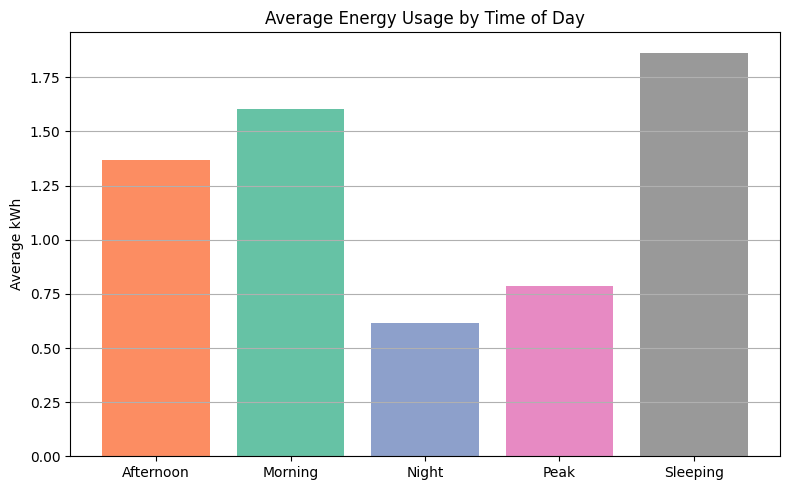

In [29]:
df = hourly_df.copy()
df.reset_index(inplace=True)  # Moves start_time from index to column
df['datetime'] = pd.to_datetime(df['start_time'])  # ✅ Now create a datetime column

df['hour'] = df['datetime'].dt.hour

def assign_time_of_day(hour):
    if 18 <= hour < 21:
        return 'Peak'
    elif 21 <= hour < 24:
        return 'Night'
    elif 0 <= hour < 6:
        return 'Sleeping'
    elif 6 <= hour < 12:
        return 'Morning'
    else:
        return 'Afternoon'

df['time_of_day'] = df['hour'].apply(assign_time_of_day)
print(df.columns)
print(df['consumption'].dtype)
df['consumption'] = pd.to_numeric(df['consumption'], errors='coerce')
df = df.dropna(subset=['consumption'])

grouped_df = df.groupby("time_of_day")["consumption"].mean().reset_index()
grouped_df.columns = ["Time of Day", "Average kWh"]

import matplotlib.pyplot as plt

# 🟦 1. Bar Plot: Average kWh by Time of Day
plt.figure(figsize=(8, 5))
color_map = {
    'Sleeping': '#999999',
    'Morning': '#66c2a5',
    'Afternoon': '#fc8d62',
    'Peak': '#e78ac3',
    'Night': '#8da0cb'
}
colors = [color_map.get(tod, '#cccccc') for tod in grouped_df["Time of Day"]]

plt.bar(grouped_df["Time of Day"], grouped_df["Average kWh"], color=colors)
plt.title("Average Energy Usage by Time of Day")
plt.ylabel("Average kWh")
plt.grid(axis='y')
plt.tight_layout()
plt.show()





In [30]:
usage_summary = grouped_df.to_string(index=False)

summary = f"""
Here is my average energy usage during different times of day:

{grouped_df.to_string(index=False)}

Please analyze which period uses the most energy and suggest 1 or 2 behavioral changes to reduce peak usage.
"""
response = chat.send_message(summary)
Markdown(response.text)


Okay, let's analyze this time-of-day usage:

**Analysis:**

*   The period with the highest average energy usage is **"Sleeping"** at **1.86 kWh** (average per hour during that period).
*   The second highest is "Morning" at 1.60 kWh.
*   Your defined "Peak" period actually has relatively low average usage (0.78 kWh) compared to "Sleeping", "Morning", and "Afternoon".

It seems counterintuitive, but the highest consumption happens while you're asleep. Based on our previous discussion about the cold spell and heat pump, this strongly suggests your **heating system is working hardest overnight** to maintain the set temperature, possibly using the less efficient auxiliary heat frequently during those coldest nighttime hours.

**Behavioral Change Suggestions to Reduce Highest Usage (Overnight/Sleeping):**

Since your *highest* usage occurs during the "Sleeping" period (not the "Peak" period), here are the most impactful behavioral changes:

1.  **Overnight Thermostat Setback:** Lower your thermostat setting by several degrees (e.g., 4-7°F or 2-4°C) before you go to bed. Your body needs less heating when you're under blankets. This directly reduces how often the heating system (especially expensive auxiliary heat) needs to run during the coldest part of the day. Use a programmable or smart thermostat to automate this.
2.  **Check Appliance Timers:** Ensure high-energy appliances like dishwashers, clothes dryers, or potentially EV chargers (if applicable) aren't scheduled to run primarily during this "Sleeping" period. While heating is the most likely culprit, shifting other loads away from this high-usage time can also contribute small savings. If possible, shift them to the lower "Night" or "Peak" periods as defined in your data, or ideally to daytime off-peak hours if your utility offers them.

Focusing on reducing energy use during the "Sleeping" hours, primarily via thermostat adjustments, will likely yield the most significant savings based on this data.

In [31]:
zero_consumption_df = df[df['consumption'] <= 0.001]  # Use <= 0.01 for near-zero values
zero_counts = zero_consumption_df['time_of_day'].value_counts().reset_index()
zero_counts.columns = ['Time of Day', 'Zero Usage Count']
print(zero_counts)


  Time of Day  Zero Usage Count
0       Night               559
1        Peak               546
2   Afternoon               309
3    Sleeping               143
4     Morning                 9


  Time of Day  Zero Usage Count  Total Count  Zero Usage %
0       Night               559         1101     50.772025
1        Peak               546         1101     49.591281
2   Afternoon               309         2202     14.032698
3    Sleeping               143         2202      6.494096
4     Morning                 9         2203      0.408534


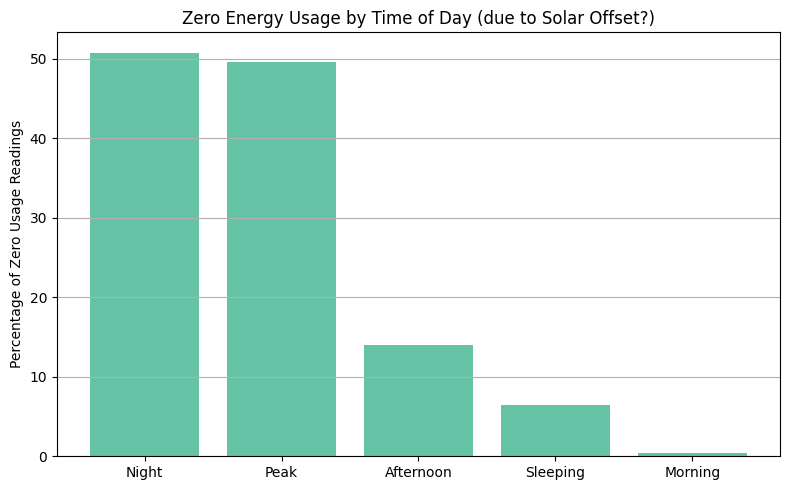

In [32]:
total_counts = df['time_of_day'].value_counts().reset_index()
total_counts.columns = ['Time of Day', 'Total Count']

# Merge and compute percentage
merged = pd.merge(zero_counts, total_counts, on='Time of Day')
merged['Zero Usage %'] = (merged['Zero Usage Count'] / merged['Total Count']) * 100

print(merged.sort_values('Zero Usage %', ascending=False))
plt.figure(figsize=(8, 5))
plt.bar(merged['Time of Day'], merged['Zero Usage %'], color="#66c2a5")
plt.ylabel("Percentage of Zero Usage Readings")
plt.title("Zero Energy Usage by Time of Day (due to Solar Offset?)")
plt.grid(axis='y')
plt.tight_layout()
plt.show()
